# TP3 – Predicción Lineal

# Grupo N° 4

| Integrante | Legajo |
|---|---|
| *Pedro Stefoni Rey Iraola* | *64903* |
| *Vito Pensa Piccolo* | *63426* |
| *Javier Baltasar Pérez Losada* | *64589* |

**Fecha de entrega:** 15/10/2026

## 1. 

Los audios de los sonidos /a/ y /sh/ fueron grabados con Audacity. La frecuencia de muestreo que se usó es de 16 kHz, canal mono, duración 1 segundo, formato WAV (sin compresión) y codificación PCM 16-bit, que para un segundo a 16 kHz equivale a 256 kbps, como se puede ver en la figura.

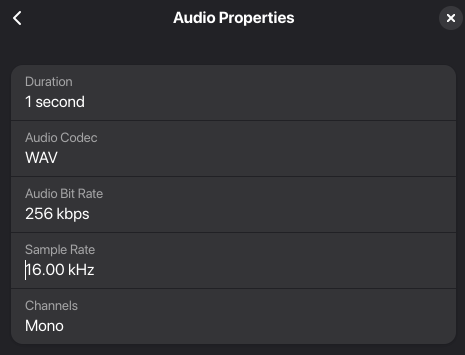

A simple vista, la señal que corresponde a /a/, tiene aspecto cuasi-periódico

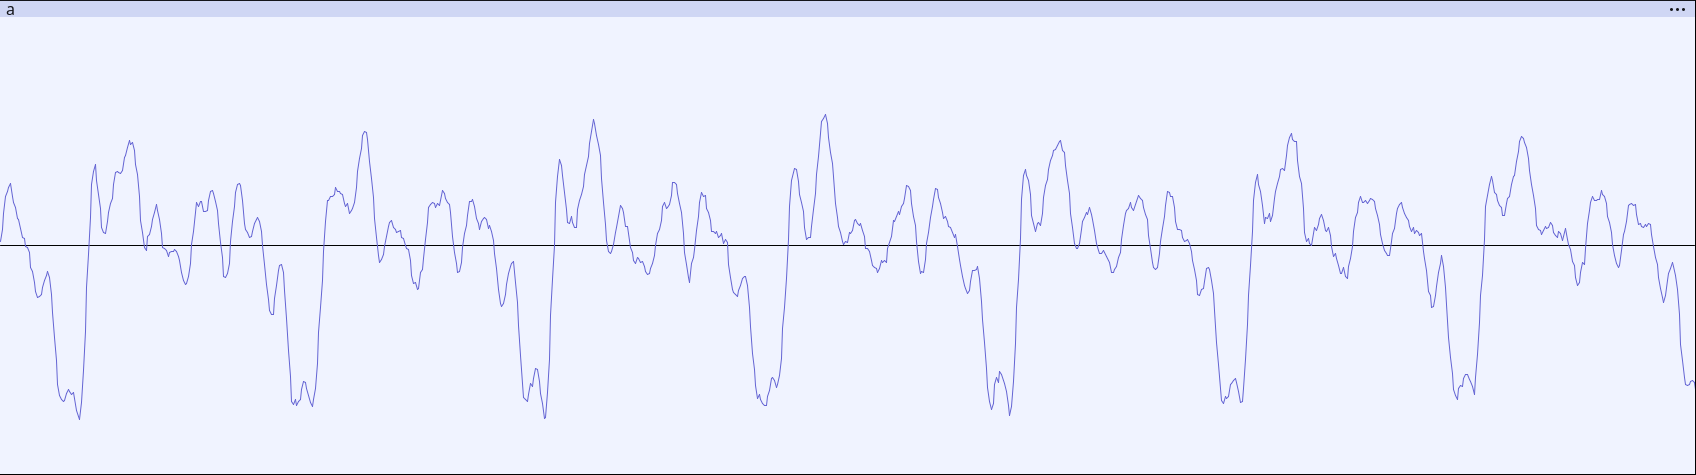

Con un periodo equivalente a $N_0=138$ muestras (este valor parece ser más exacto que la medición de segundos en Audacity), lo que equivale a 
$$ f_0 = \frac{f_s}{N_0} \approx 116\;\text{Hz.}$$

Por otro lado, la señal que corresponde a /sh/, tanto en su aspecto en el tiempo como psicoacústico, tiene toda la pinta de ruido blanco.

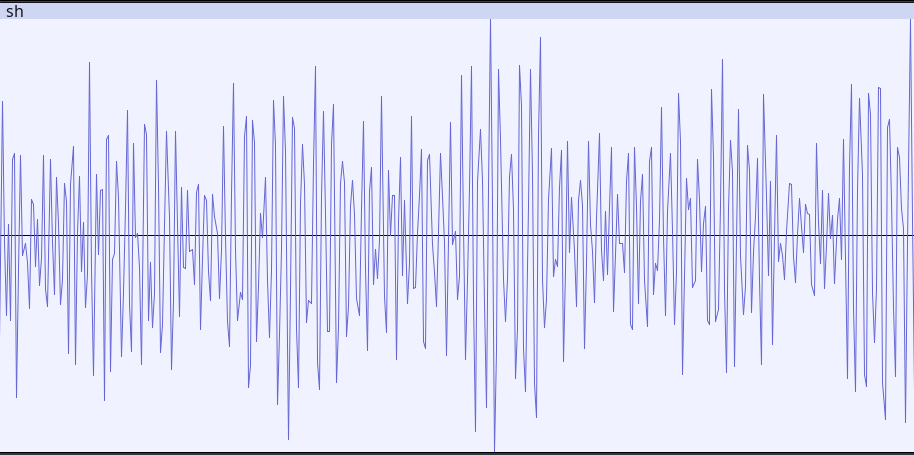

## 2.

Con la siguiente celda se calculan el FLP para /a/ y /sh/. Utilizamos el algoritmo de Levinson-Durbin, ya que es idóeo para estre problema, ya que es un problema de de predicción, i.e. un sistema de ecuaciones Toeplitz. Se grafica $J(M)$ y el error para distintos valores de $M$. 


/a/: 16010 muestras, 1.001 s, fs=16000 Hz
/sh/: 16022 muestras, 1.001 s, fs=16000 Hz


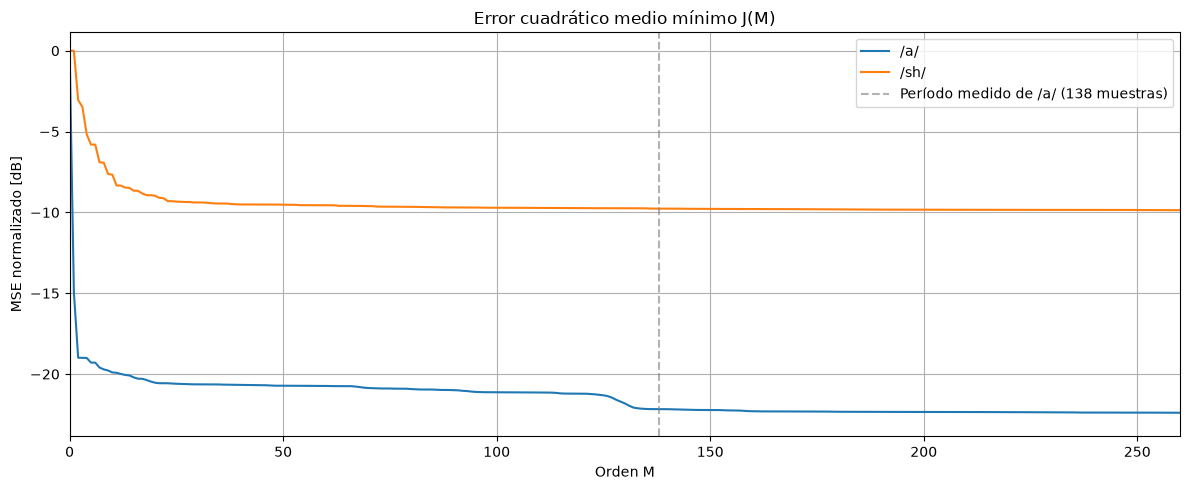

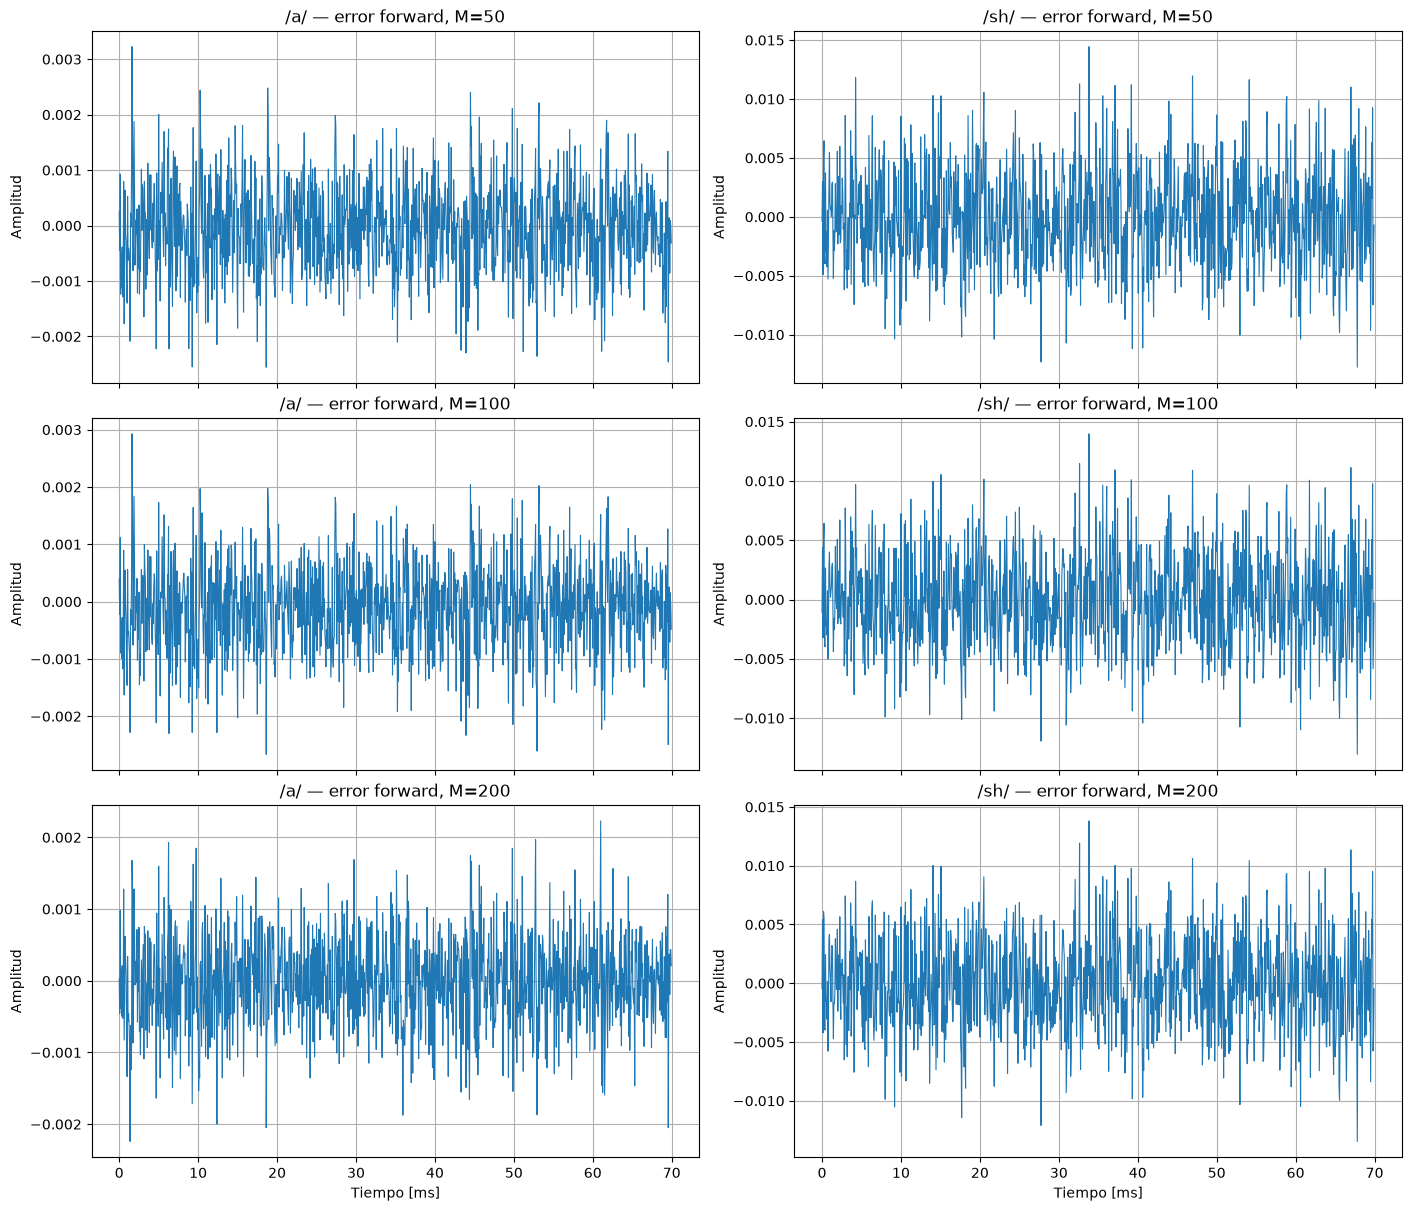

In [ ]:

import numpy as np
import soundfile as sf
import matplotlib.pyplot as plt
from scipy.signal import correlate, lfilter

# Parámetros
ARCHIVOS = {"a": "./audio/a.wav", "sh": "./audio/sh.wav"}
FS = 16000
M_MAX = 1000 # Valor razonable


def autocorrelacion(x, M):
    """Autocorrelación sesgada: r[l] = (1/N) * sum(x[n]*x[n-l])."""
    N = len(x)
    return correlate(x, x, mode="full", method="fft")[N-1:N+M] / N


def levinson_durbin(r, M):
    """
    Predicción forward óptima para órdenes 0,...,M.
    Devuelve:
        J[m]: MSE mínimo para orden m
        A[m]: coeficientes [1, a1, ..., am] del filtro de error
    """
    J = np.empty(M + 1)
    J[0] = r[0]
    A = [np.array([1.0])]

    for m in range(1, M + 1):
        a_prev = A[-1]

        # Correlación residual
        beta = r[m] + np.dot(a_prev[1:], r[m-1:0:-1])

        # Coeficiente de reflexión
        k = -beta / J[m-1]

        # Actualización de los coeficientes del predictor
        a = np.append(a_prev, 0.0)
        a[1:m] = a_prev[1:] + k * a_prev[1:][::-1]
        a[m] = k

        # Actualización del MSE mínimo
        J[m] = J[m-1] * (1 - k**2)

        A.append(a)

    return J, A


# Procesamiento de las grabaciones completas
resultados = {}

for sonido, archivo in ARCHIVOS.items():
    x, fs = sf.read(archivo)

    assert fs == FS, f"{archivo}: frecuencia de muestreo incorrecta ({fs} Hz)"
    assert x.ndim == 1, f"{archivo}: el audio debe ser mono"

    x = x - np.mean(x)  # Eliminar componente continua

    r = autocorrelacion(x, M_MAX)
    J, A = levinson_durbin(r, M_MAX)

    resultados[sonido] = {"x": x, "r": r, "J": J, "A": A}
    print(f"/{sonido}/: {len(x)} muestras, {len(x)/FS:.3f} s, fs={fs} Hz")


# ============================================================
# 1. MSE mínimo J(M) — ambas señales superpuestas
# ============================================================

fig, ax = plt.subplots(figsize=(12, 5))

M_GRAFICO = 260  # Solo limita la visualización, no el cálculo

for sonido in ("a", "sh"):
    J = resultados[sonido]["J"]
    J_dB = 10 * np.log10(J / J[0])

    ax.plot(np.arange(len(J)), J_dB, label=f"/{sonido}/", linewidth=1.5)

ax.axvline(138, color="gray", linestyle="--", alpha=0.6,
           label="Período medido de /a/ (138 muestras)")

ax.set_xlim(0, min(M_GRAFICO, M_MAX))
ax.set_xlabel("Orden M")
ax.set_ylabel("MSE normalizado [dB]")
ax.set_title("Error cuadrático medio mínimo J(M)")
ax.legend()
ax.grid(True)

plt.tight_layout()
plt.show()


# ============================================================
# 2. Error de predicción forward para distintos órdenes M
# ============================================================

ORDENES_ERROR = [50, 100, 200]

T_INICIO = 0.30
T_FIN = 0.37  # 70 ms, aproximadamente 8 períodos de /a/

i0 = int(T_INICIO * FS)
i1 = int(T_FIN * FS)

t = np.arange(i1 - i0) / FS * 1000  # Tiempo relativo en ms

fig, axes = plt.subplots(
    len(ORDENES_ERROR), 2,
    figsize=(14, 12),
    sharex=True,
    layout="constrained"
)

for col, sonido in enumerate(("a", "sh")):
    x = resultados[sonido]["x"]
    A = resultados[sonido]["A"]

    for fila, M in enumerate(ORDENES_ERROR):
        # Filtro del error de predicción: A(z)
        e = lfilter(A[M], [1.0], x)

        ax = axes[fila, col]
        ax.plot(t, e[i0:i1], linewidth=0.8)

        ax.set_title(f"/{sonido}/ — error forward, M={M}")
        ax.set_ylabel("Amplitud")
        ax.grid(True)

        if fila == len(ORDENES_ERROR) - 1:
            ax.set_xlabel("Tiempo [ms]")

plt.show()


Es notable que para el "segundo codo" de $J(M)$ de /a/ se da luego de $N_0$. Con la ayuda de un LLM (GPT-6), interpretamos esto a partir del modelo fuente-filtro de la voz: la vocal /a/ se genera por una excitación glotal cuasiperiódica (vibración de las cuerdas vocales) filtrada por las resonancias del tracto vocal. El primer codo se asocia principalmente al modelado de ese filtro vocal, mientras que el segundo aparece cuando el predictor alcanza retardos del orden de $N_0$ y comienza a explotar también la periodicidad de la excitación glotal.

Para poder analizar qué le sucede a la señal de error _forward_ de /a/ y qué componentes armónicas están más presentes en la señal, le aplicamos una FFT con ventana de Hann; ya que las mediciones temporales son muy ruidosas como para poder inferir algo. Sólo se gráfica $e^f(n)$ de /a/, dado que, como se dijo antes, la señal de /sh/ es prácticamente ruido blanco.

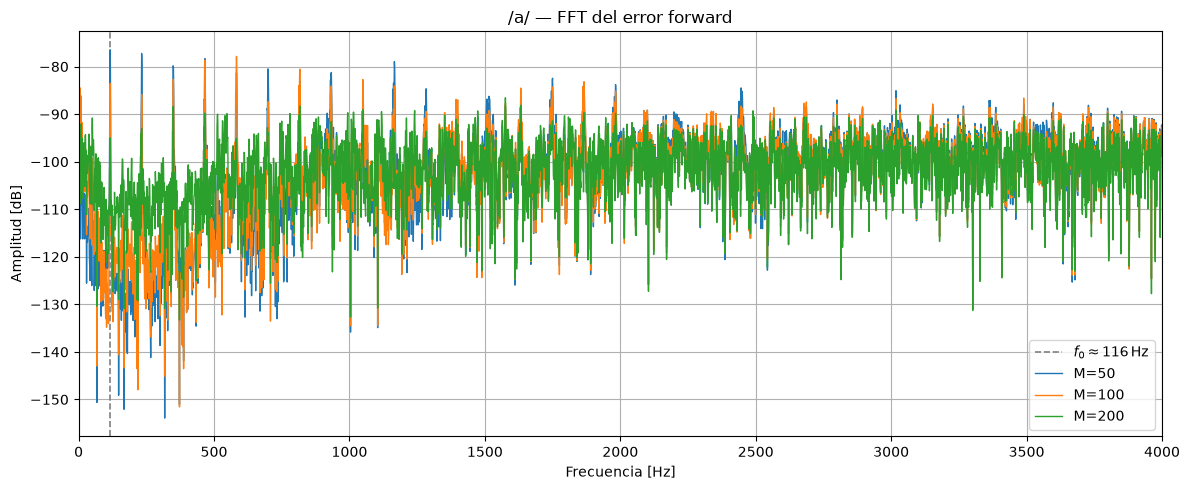

In [25]:
FMAX = 4000
F0 = 116  # Hz

fig, ax = plt.subplots(figsize=(12, 5))

x = resultados["a"]["x"]
A = resultados["a"]["A"]

# descartar primeras muestras para evitar transitorio del filtrado
n0 = max(ORDENES_ERROR)
N = len(x) - n0

ventana = np.hanning(N)
frecuencias = np.fft.rfftfreq(N, d=1/FS)

ax.axvline(F0, color="grey", linestyle="--", linewidth=1.2,
           label=fr"$f_0 \approx {F0}\,$Hz")

for M in ORDENES_ERROR:
    e = lfilter(A[M], [1.0], x)
    e = e[n0:]

    E = np.fft.rfft(e * ventana)

    magnitud = np.abs(E) / np.sum(ventana)
    if N % 2 == 0:
        magnitud[1:-1] *= 2
    else:
        magnitud[1:] *= 2

    magnitud_dB = 20 * np.log10(np.maximum(magnitud, 1e-12))
    ax.plot(frecuencias, magnitud_dB, label=f"M={M}", linewidth=1)

ax.set_title("/a/ — FFT del error forward")
ax.set_xlabel("Frecuencia [Hz]")
ax.set_ylabel("Amplitud [dB]")
ax.set_xlim(0, FMAX)
ax.grid(True)
ax.legend()

plt.tight_layout()
plt.show()

Se puede observar así que la señal de error tiene presente los armónicos correspondientes a $nf_0$. También podemos ver que la energía de estos armónicos baja sustancialmente luego de $M=100$ (o sea $M>N_0$), como supusimos antes. De todas formas, aun luego del "2do codo" de $J(M)$, sigue presente energía en $nf_0$ para $M=200$, es como si el FLP no estuviese "blanqueando" $x(n)$. Esto se debe a múltiples razones:

1. La primera es que el predictor óptimo minimiza la potencia total del error, pero esto no implica que elimine completamente las componentes armónicas de la señal. Para entender esto más claramente, veamos un ejemplo.

Para ver esto, consideremos una señal formada por una componente perfectamente periódica $s(n)$, de período $N_0$, y ruido blanco $w(n)$:

$$
x(n)=s(n)+w(n), \qquad s(n)=s(n-N_0)
$$

Y supongamos un predictor que utiliza únicamente la muestra ubicada un período atrás:

$$
\hat{x}(n)=cx(n-N_0)
$$

Luego $e^f$ resulta:

$$
e^f(n)=(1-c)s(n)+w(n)-cw(n-N_0)
$$

Para eliminar completamente la componente periódica, deberíamos elegir $c=1$. Sin embargo, esto produciría $e^f(n)=w(n)-w(n-N_0)$, cuya potencia es $J(1)=2\sigma_w^2$.

En cambio, minimizando el MSE respecto de $c$:

$$
J(c)=(1-c)^2\sigma_s^2+(1+c^2)\sigma_w^2
$$

obtenemos:

$$
\boxed{c_o=\frac{\sigma_s^2}{\sigma_s^2+\sigma_w^2}}
$$

Por ejemplo, si $\sigma_s^2=9$ y $\sigma_w^2=1$, entonces $c_o=0.9$ y:

$$
e^f(n)=0.1s(n)+w(n)-0.9w(n-N_0)
$$

En este caso, $J(0.9)=1.9$, mientras que $J(1)=2$. Por tanto, conservar el 10 % de la amplitud periódica permite obtener un MSE menor que eliminarla completamente, ya que se reduce la contribución del ruido de la muestra anterior.

Y aun así, se cumple el principio de ortogonalidad:

$$
\mathbb{E}\{e^f(n)x(n-N_0)\}
=0.1(9)-0.9(1)=0
$$

O sea, el error puede ser incorrelacionado con la entrada retrasada y, al mismo tiempo, conservar componentes armónicas. Esto ocurre porque las contribuciones a la correlación se cancelan entre sí.

2. Después, la excitación glotal no es perfectamente periódica; ya que existen pequeñas variaciones en el período, la amplitud y la forma de los pulsos producidos por las cuerdas vocales. Por lo tanto, las muestras de un ciclo anterior no permiten predecir exactamente las del ciclo actual.

3. Y por último, los coeficientes del predictor se calculan mediante Levinson-Durbin utilizando una autocorrelación estimada $\hat r_x(l)$ a partir de una realización finita de la señal. Entonces, los coeficientes obtenidos no coinciden necesariamente con los óptimos teóricos. Además, se utiliza el estimador sesgado de autocorrelación, que atenúa las correlaciones estimadas para retardos grandes.

## 3.


/a/
M	J(M)/J(0) [dB]
1	-14.94
2	-18.99
4	-19.00
8	-19.71
16	-20.28
32	-20.64
64	-20.75

/sh/
M	J(M)/J(0) [dB]
1	-0.01
2	-3.05
4	-5.17
8	-6.92
16	-8.66
32	-9.40
64	-9.59


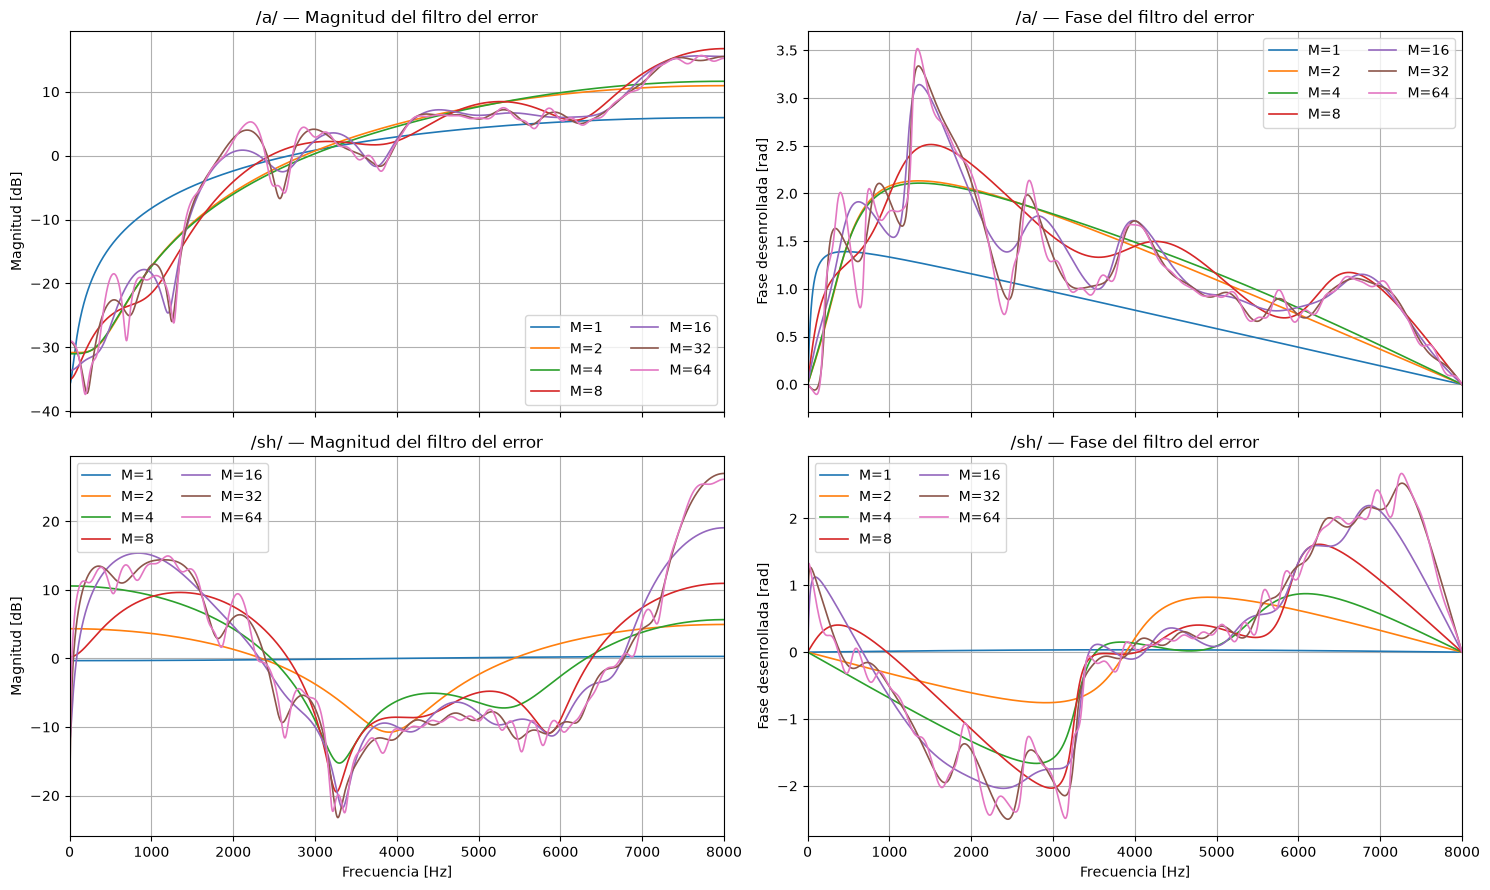

In [26]:

from scipy.signal import freqz

ORDENES_P3 = [1, 2, 4, 8, 16, 32, 64]
FMAX = 8000  # Hz (frecuencia de Nyquist)

fig, axes = plt.subplots(2, 2, figsize=(15, 9), sharex=True)

for fila, sonido in enumerate(("a", "sh")):
    A = resultados[sonido]["A"]
    J = resultados[sonido]["J"]

    ax_mag = axes[fila, 0]
    ax_fase = axes[fila, 1]

    print(f"\n/{sonido}/")
    print("M\tJ(M)/J(0) [dB]")

    for M in ORDENES_P3:
        # Coeficientes del filtro del error:
        # H(z) = 1 + a1*z^-1 + ... + aM*z^-M
        b = A[M]

        # Respuesta en frecuencia compleja H(e^jw)
        f, H = freqz(b, a=[1.0], worN=8192, fs=FS)

        magnitud_dB = 20 * np.log10(np.maximum(np.abs(H), 1e-12))
        fase = np.unwrap(np.angle(H))

        ax_mag.plot(f, magnitud_dB, label=f"M={M}", linewidth=1.2)
        ax_fase.plot(f, fase, label=f"M={M}", linewidth=1.2)

        # MSE mínimo normalizado para este orden
        J_dB = 10 * np.log10(J[M] / J[0])
        print(f"{M}\t{J_dB:.2f}")

    ax_mag.set_title(f"/{sonido}/ — Magnitud del filtro del error")
    ax_mag.set_ylabel("Magnitud [dB]")
    ax_mag.set_xlim(0, FMAX)
    ax_mag.legend(ncol=2)
    ax_mag.grid(True)

    ax_fase.set_title(f"/{sonido}/ — Fase del filtro del error")
    ax_fase.set_ylabel("Fase desenrollada [rad]")
    ax_fase.set_xlim(0, FMAX)
    ax_fase.legend(ncol=2)
    ax_fase.grid(True)

axes[1, 0].set_xlabel("Frecuencia [Hz]")
axes[1, 1].set_xlabel("Frecuencia [Hz]")

plt.tight_layout()
plt.show()


Acá podemos ver cómo las respuestas en frecuencia del filtro del error aumentan la capacidad del predictor para modelar la estructura espectral de las señales a medida que crece su orden $M$.

Para /a/, se observa una fuerte atenuación de las bajas frecuencias y la aparición de mínimos locales (que pueden relacionarse con las resonancias del tracto vocal (formantes)). Para /sh/, a pesar de tratarse de una consonante sorda con excitación principalmente aleatoria, se observa una respuesta espectral selectiva, evidenciando que la señal presenta correlaciones de corto plazo.

En ambos casos, las respuestas para órdenes elevados ($M=16,32,64$) conservan una estructura general similar, lo que indica que buena parte de la información predecible de corto plazo ya ha sido modelada. Esto es consistente con el primer codo observado en $J(M)$.

Dado que los órdenes analizados son inferiores al período fundamental estimado para /a/ ($N_0=138$), con éstos gráficos podemos observar el modelado del tracto vocal, pero no caracterizar directamente el 2do codo asociado a la periodicidad glotal.